# 1 · Make data model-ready: gaps, words and rulers

**What you practise (from the feature-engineering lecture):**
- **Split first**, then learn everything from the training rows only.
- **fit = learn, transform = apply.**
- **Imputation:** filling gaps on purpose. *Missing ≠ zero.*
- **Encoding:** turning words into numbers *without inventing an order*.
- **Scaling:** choosing the ruler (MinMax, Standard, Robust) and what none of them do.
- **Log** for very skewed numbers.

## 🐧 The case: PenguinTrack

Field researchers in Antarctica track thousands of penguins. **Weighing** a penguin is slow, needs two people, and stresses the bird. Measuring its beak and flipper with a caliper takes ten seconds.

**Ana**, the PM of the **PenguinTrack** research app, asks you:

*"Could the app **estimate a penguin's weight** from the quick measurements (plus species, island and sex), so the team only weighs the birds where the estimate is unsure?"*

Before any model can learn this, the raw table has to become **model-ready**: no gaps, only numbers, sensible scales. That is today's job.

> 📌 The data is real: the *Palmer Penguins* dataset (342 penguins). We predict a **number** (grams), so this is **regression**, not yes/no. That doesn't matter today: filling gaps, encoding words and scaling work exactly the same for churn models. **No model is trained in this notebook**: we only prepare the inputs.

<img src="../assets/feature_eng.png" width="460" alt="Raw data is transformed into features before model training">

> **How this notebook works**
> - Run the cells **from top to bottom** with `Shift + Enter`.
> - ▶️ **Run** cells work as they are.
> - ✏️ **Your turn** cells contain `___` (three underscores). Replace each `___` with your answer, then run the cell.
> - ✅ **Check** cells tell you whether you got it right. If a check fails, read the hint, fix the cell above and run both again.
> - 🧠 **Think** cells ask a PM question. Double-click the answer cell below it and write 1–3 sentences.
> - If you see `NameError: name '___' is not defined`, a blank is still empty.
> - Stuck? The `solutions/` folder has the same notebook, solved.

## Step 0 · Load the tools

In [1]:
# ▶️ Run: load the libraries we need
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, MinMaxScaler, StandardScaler, RobustScaler

print("Ready!")

Ready!


## Step 1 · Meet the data

In [2]:
# ▶️ Run: read the file and show the first five penguins
penguins = pd.read_csv("../data/penguins.csv")
penguins.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female
4,Adelie,Torgersen,39.3,20.6,190.0,3650.0,Male


| column | meaning | type |
|---|---|---|
| `species` | Adelie, Chinstrap or Gentoo | words (category) |
| `island` | Biscoe, Dream or Torgersen | words (category) |
| `bill_length_mm`, `bill_depth_mm` | beak length and depth | number |
| `flipper_length_mm` | flipper length | number |
| `sex` | Female or Male | words (category) |
| **`body_mass_g`** | **target**: weight in grams (what Ana wants to estimate) | number |

In [3]:
# ✏️ Your turn: how many penguins (rows) and columns are there?
# Hint: a DataFrame has an attribute that gives (rows, columns).
n_rows, n_columns = penguins.shape
print(n_rows, "penguins,", n_columns, "columns")

342 penguins, 7 columns


In [4]:
# ✅ Check
assert (n_rows, n_columns) == (342, 7), "Not quite. Try penguins.shape"
print("✅ Correct: 342 penguins, 7 columns (6 inputs + the target).")

✅ Correct: 342 penguins, 7 columns (6 inputs + the target).


## Step 2 · Split first, before you look for anything

The **test set** plays the role of *future* penguins: birds the app will meet next season. So we put it aside **now**, before we learn anything from the data. Every number we learn today (a median, a list of categories, a scale) must come from the **training** rows only.

In [5]:
# ▶️ Run: inputs (X) and target (y)
X = penguins.drop(columns="body_mass_g")
y = penguins["body_mass_g"]

In [6]:
# ✏️ Your turn: keep 25% of the penguins aside as the test set (write it as a decimal)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
print("train:", X_train.shape[0], "penguins | test:", X_test.shape[0], "penguins")

train: 256 penguins | test: 86 penguins


In [7]:
# ✅ Check
assert len(X_train) == 256 and len(X_test) == 86, "test_size should be 0.25 (a quarter)."
print("✅ Correct: 256 penguins to learn from, 86 kept aside as 'next season'.")

✅ Correct: 256 penguins to learn from, 86 kept aside as 'next season'.


🧠 **Think:** why do we split *before* we even count the gaps or compute a median?

**✍️ Sample answer:** Because the test set stands in for future penguins we haven't met yet. If the median (or any other number) is learned from all rows, the test rows have already influenced the preparation, so the test score is no longer an honest rehearsal of production. Split first, learn from training rows, then only *apply* to the test rows.

## Step 3 · Find the gaps

Most models (logistic regression, KNN, linear regression) simply **refuse to run** if a single cell is empty. So first: where are the gaps?

In [8]:
# ✏️ Your turn: count the missing values per column in the TRAINING inputs
# Hint: one method marks every empty cell as True; .sum() then counts them.
gaps = X_train.isna().sum()
gaps

species              0
island               0
bill_length_mm       0
bill_depth_mm        2
flipper_length_mm    2
sex                  6
dtype: int64

In [9]:
# ✅ Check
assert gaps["sex"] == 6 and gaps["bill_depth_mm"] == 2 and gaps["flipper_length_mm"] == 2, "Use X_train.isna().sum()"
print("✅ Correct: sex has 6 gaps, bill depth 2, flipper length 2.")

✅ Correct: sex has 6 gaps, bill depth 2, flipper length 2.


**What can we do with an empty cell?**

| option | what it does | side effect |
|---|---|---|
| drop the row | throw the penguin away | you lose data, and in production you **can't drop** a penguin you need to estimate |
| fill with the **mean** | average of the training values | pulled around by a few extreme values |
| fill with the **median** | middle training value | robust to extremes: the usual default for numbers |
| fill with the **most frequent** | the most common category | the usual choice for words (you can't average "Male" and "Female") |
| add a **"was missing" flag** | an extra 0/1 column | useful when *being missing* itself means something |

> ⚠️ **Missing ≠ zero.** A customer who never answered the NPS survey did **not** give you a 0 ("I'd never recommend you"). We simply don't know. Filling with 0 tells the model "this customer hates us".

In [10]:
# ✏️ Your turn: how many training penguins would we lose if we simply dropped every row with a gap?
rows_left = len(X_train.dropna())
print("Rows left:", rows_left, "of", len(X_train), "→ lost", len(X_train) - rows_left)

Rows left: 247 of 256 → lost 9


In [11]:
# ✅ Check
assert rows_left == 247, "Use X_train.dropna(), which removes every row with at least one gap."
print("✅ Correct: 9 penguins lost. Small here, but with 20 columns the losses add up quickly.")

✅ Correct: 9 penguins lost. Small here, but with 20 columns the losses add up quickly.


## Step 4 · Imputation: fill the gaps (fit = learn, transform = apply)

`SimpleImputer` works in two steps, like every preparation tool in scikit-learn:

| method | what it does | example |
|---|---|---|
| `.fit(X_train)` | **learns** a number from the training rows and stores it | "the most frequent sex is …" |
| `.transform(X)` | **applies** the stored number to any rows you give it. Learns nothing. | fill every gap with that value |
| `.fit_transform(X_train)` | both at once: only ever on **training** rows | |

### 4a · `sex`: a word column → most frequent value

In [12]:
# ▶️ Run: what does the training data contain?
X_train["sex"].value_counts(dropna=False)

sex
Female    127
Male      123
NaN         6
Name: count, dtype: int64

In [13]:
# ✏️ Your turn: which strategy fills a WORD column? ("mean", "median" or "most_frequent")
sex_imputer = SimpleImputer(strategy="most_frequent").set_output(transform="pandas")
sex_imputer.fit(X_train[["sex"]])          # learn from TRAINING rows only
print("Learned fill value:", sex_imputer.statistics_)

Learned fill value: ['Female']


In [14]:
# ✅ Check
assert sex_imputer.statistics_[0] == "Female", "Words can't be averaged. Use 'most_frequent'."
print("✅ Correct: 127 Female vs 123 Male in training, so the imputer learned 'Female'.")

✅ Correct: 127 Female vs 123 Male in training, so the imputer learned 'Female'.


In [15]:
# ✏️ Your turn: now fill the gaps in the TEST rows. fit or transform?
sex_test_filled = sex_imputer.transform(X_test[["sex"]])
print("Gaps left in test:", sex_test_filled["sex"].isna().sum())
print("Test penguins (before filling):", X_test["sex"].value_counts(dropna=False).to_dict())

Gaps left in test: 0
Test penguins (before filling): {'Male': 45, 'Female': 38, nan: 3}


In [16]:
# ✅ Check
assert sex_test_filled["sex"].isna().sum() == 0 and sex_imputer.statistics_[0] == "Female", \
    "Use .transform on the test rows, so the imputer keeps what it learned from training."
print("✅ Correct: the 3 test gaps were filled with 'Female', learned from training.")

✅ Correct: the 3 test gaps were filled with 'Female', learned from training.


🧠 **Think:** the test rows contain *more* males (45) than females (38), yet the 3 missing test penguins were filled with "Female". Is that a bug?

**✍️ Sample answer:** No. In production we don't know anything about next season's penguins either: we can only use what we learned from the training data. Treating the test rows exactly like future rows (transform only) makes the test an honest rehearsal. Re-learning from the test rows would let the "exam" shape the preparation.

### 4b · The number columns → median

In [17]:
# ✏️ Your turn: fill the three number columns with their TRAINING median
number_columns = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm"]
number_imputer = SimpleImputer(strategy="median").set_output(transform="pandas")
number_imputer.fit(X_train[number_columns])
print("Learned medians:", dict(zip(number_columns, number_imputer.statistics_.tolist())))

Learned medians: {'bill_length_mm': 45.1, 'bill_depth_mm': 17.3, 'flipper_length_mm': 198.0}


In [18]:
# ✅ Check
assert list(number_imputer.statistics_) == [45.1, 17.3, 198.0], "Use strategy='median'."
print("✅ Correct: the medians were learned from the 256 training penguins.")

✅ Correct: the medians were learned from the 256 training penguins.


In [19]:
# ▶️ Run: the optional "was missing" flag. add_indicator=True adds one 0/1 column per column that had gaps
flag_imputer = SimpleImputer(strategy="median", add_indicator=True).set_output(transform="pandas")
flag_imputer.fit_transform(X_train[number_columns]).loc[X_train[number_columns].isna().any(axis=1)]

,bill_length_mm,bill_depth_mm,flipper_length_mm,missingindicator_bill_depth_mm,missingindicator_flipper_length_mm
323,47.3,13.8,198.0,0.0,1.0
30,37.2,18.1,198.0,0.0,1.0
190,53.5,17.3,205.0,1.0,0.0
50,40.1,17.3,188.0,1.0,0.0


🧠 **Think:** TeamFlow's `nps_score` is empty for most customers. Would you fill it with 0, with the median, or with the median **plus** a "was missing" flag? Why?

**✍️ Sample answer:** Median plus a flag. 0 is a real (very bad) score, so filling with 0 would tell the model that silent customers are furious. The median keeps the number neutral, and the flag lets the model learn whether *not answering* is itself a signal (silent customers are often less engaged).

## Step 5 · Encoding: turn words into numbers, without inventing an order

### 5a · The lazy way and why it lies

In [20]:
# ▶️ Run: the "lazy" way: number the species 0, 1, 2 (alphabetically)
lazy_codes = {"Adelie": 0, "Chinstrap": 1, "Gentoo": 2}
X_train["species"].map(lazy_codes).head()

24     0
323    2
143    0
208    1
253    2
Name: species, dtype: int64

A model that does maths with these codes now believes that a Gentoo (2) is "twice as far" from an Adelie (0) as a Chinstrap (1) is, and that a Chinstrap is the *average* of the other two. None of that is true: species have **no order**.

### 5b · One-hot: one yes/no column per category

In [21]:
# ✏️ Your turn: one-hot encode species. Drop the FIRST category, so Adelie becomes the "all zeros" reference.
species_encoder = OneHotEncoder(drop="first", sparse_output=False).set_output(transform="pandas")
species_encoder.fit(X_train[["species"]])
species_train = species_encoder.transform(X_train[["species"]])
print("Categories learned:", list(species_encoder.categories_[0]))
print("New columns:", list(species_encoder.get_feature_names_out()))
pd.concat([X_train[["species"]], species_train], axis=1).head()

Categories learned: ['Adelie', 'Chinstrap', 'Gentoo']
New columns: ['species_Chinstrap', 'species_Gentoo']


,species,species_Chinstrap,species_Gentoo
24,Adelie,0.0,0.0
323,Gentoo,0.0,1.0
143,Adelie,0.0,0.0
208,Chinstrap,1.0,0.0
253,Gentoo,0.0,1.0


In [22]:
# ✅ Check
assert list(species_encoder.get_feature_names_out()) == ["species_Chinstrap", "species_Gentoo"], "Use drop='first'."
print("✅ Correct: 2 columns. Both 0 means Adelie, the reference category.")

✅ Correct: 2 columns. Both 0 means Adelie, the reference category.


### 5c · When numbers in order ARE right: ordinal encoding

Some categories **do** have a real order, for example a subscription tier: `free` < `basic` < `premium`. Then numbers in that order make sense, **if you write the order down yourself** (otherwise scikit-learn sorts alphabetically: basic, free, premium!).

In [23]:
# ✏️ Your turn: write the tiers in their REAL order, from lowest to highest
tiers = pd.DataFrame({"plan": ["premium", "free", "basic", "free", "premium"]})
tier_encoder = OrdinalEncoder(categories=[["free", "basic", "premium"]]).set_output(transform="pandas")
tiers.assign(plan_code=tier_encoder.fit_transform(tiers)["plan"])

,plan,plan_code
0,premium,2.0
1,free,0.0
2,basic,1.0
3,free,0.0
4,premium,2.0


In [24]:
# ✅ Check
assert list(tier_encoder.categories_[0]) == ["free", "basic", "premium"], "Lowest first: free, basic, premium."
print("✅ Correct: free → 0, basic → 1, premium → 2.")

✅ Correct: free → 0, basic → 1, premium → 2.


🧠 **Think:** why is one-hot right for `island`, while ordinal codes are fine for the plan tier?

**✍️ Sample answer:** Islands are just names, with no ranking, so codes 0/1/2 would invent an order and distances that don't exist. Plan tiers really are ordered (free < basic < premium), so numbers in that order carry true information. (Even then, equal steps assume equal distances, which is a simplification.)

In [25]:
# ▶️ Run: next season, the team meets an Emperor penguin. The encoder only knows the 3 training species.
new_bird = pd.DataFrame({"species": ["Emperor"]})
try:
    species_encoder.transform(new_bird)
except ValueError as error:
    print("Expected error:", error)

Expected error: Found unknown categories ['Emperor'] in column 0 during transform


A fitted encoder **never learns during `transform`**. A new category means a **product decision**: stop with an error, or score it as "unknown" and alert someone? Notebook 2 lets you try both.

## Step 6 · Scaling: choosing the ruler

Some models compare columns with each other. KNN adds up distances, so a column measured in big numbers (flipper: 172–230 mm) drowns out one in small numbers (bill depth: 13–22 mm). Scaling puts all columns on a comparable ruler. **Who needs it?** KNN: yes. Regularised logistic regression: usually. Trees: no.

Each scaler **learns two numbers** in `fit` (from training data) and reuses them forever:

| scaler | learns | formula |
|---|---|---|
| MinMax | min and max | (x − min) ÷ (max − min) → training values land in 0–1 |
| Standard | mean and standard deviation | (x − mean) ÷ SD |
| Robust | median and IQR (width of the middle half) | (x − median) ÷ IQR |

Let's test them on a tiny sample: seven ordinary values and **two extreme ones** (think: support tickets, where two customers have a lot).

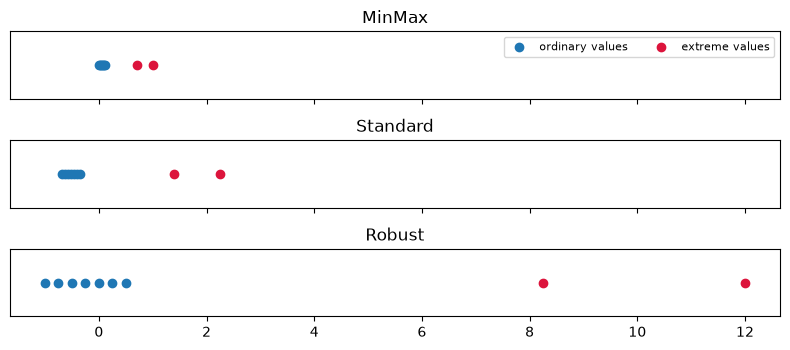

,original,MinMax,Standard,Robust
0,8,0.000,-0.691,-1.00
1,9,0.019,-0.634,-0.75
2,10,0.038,-0.578,-0.50
3,11,0.058,-0.521,-0.25
4,12,0.077,-0.465,0.00
5,13,0.096,-0.408,0.25
6,14,0.115,-0.352,0.50
7,45,0.712,1.400,8.25
8,60,1.000,2.247,12.00


In [26]:
# ▶️ Run: the same 9 values through three scalers
sample = pd.DataFrame({"x": [8, 9, 10, 11, 12, 13, 14, 45, 60]})
scaled = pd.DataFrame({
    "original": sample["x"],
    "MinMax": MinMaxScaler().fit_transform(sample).ravel(),
    "Standard": StandardScaler().fit_transform(sample).ravel(),
    "Robust": RobustScaler().fit_transform(sample).ravel(),
}).round(3)

fig, axes = plt.subplots(3, 1, figsize=(8, 3.6), sharex=True)
for ax, name in zip(axes, ["MinMax", "Standard", "Robust"]):
    ax.scatter(scaled[name][:7], [0] * 7, label="ordinary values")
    ax.scatter(scaled[name][7:], [0] * 2, color="crimson", label="extreme values")
    ax.set(title=name, yticks=[])
axes[0].legend(loc="upper right", ncol=2, fontsize=8)
plt.tight_layout(); plt.show()
scaled

In [27]:
# ✏️ Your turn: which scaler keeps the seven ordinary values nicely spread out? ("MinMax", "Standard" or "Robust")
best_for_ordinary_values = "Robust"

# ✏️ Your turn: after RobustScaler, are the extreme values gone? (True or False)
robust_removes_extremes = False

In [28]:
# ✅ Check
assert best_for_ordinary_values == "Robust", "Look at the gaps between the blue dots in each panel."
assert robust_removes_extremes is False, "Look at the table: 45 and 60 become 8.25 and 12.0. Still far away!"
print("✅ Correct: Robust learns its ruler from the ordinary values (median 12, IQR 4).")
print("   But it deletes nothing: 60 becomes 12.0, still an extreme. No scaler removes outliers.")

✅ Correct: Robust learns its ruler from the ordinary values (median 12, IQR 4).
   But it deletes nothing: 60 becomes 12.0, still an extreme. No scaler removes outliers.


In [29]:
# ▶️ Run: a new customer arrives later with the value 70, bigger than anything seen in training
minmax = MinMaxScaler().fit(sample)                 # learned min 8, max 60
print("MinMax value for 70:", minmax.transform(pd.DataFrame({"x": [70]})).round(3)[0][0])

MinMax value for 70: 1.192


🧠 **Think:** the MinMax value is above 1. Is that a bug? Should we refit the scaler including the new customer?

**✍️ Sample answer:** Not a bug. The scaler reuses the training min (8) and max (60), so a value outside the training range lands outside 0–1. We should **not** refit on new data: the model learned its weights on the training ruler, and refitting every day would turn the same customer into different numbers depending on who else is in the batch. Refitting belongs to a deliberate retraining of scaler and model together.

### 6b · Scale the penguins

In [30]:
# ✏️ Your turn: fit the scaler on the (filled) TRAINING numbers, then only APPLY it to the test numbers
numbers_train = number_imputer.transform(X_train[number_columns])
numbers_test = number_imputer.transform(X_test[number_columns])

scaler = StandardScaler().set_output(transform="pandas")
numbers_train_scaled = scaler.fit_transform(numbers_train)
numbers_test_scaled = scaler.transform(numbers_test)
numbers_train_scaled.describe().loc[["mean", "std"]].round(2)

,bill_length_mm,bill_depth_mm,flipper_length_mm
mean,0.0,0.0,-0.0
std,1.0,1.0,1.0


In [31]:
# ✅ Check
assert np.allclose(scaler.mean_, numbers_train.mean()), "Fit the scaler on the training numbers only."
assert abs(numbers_test_scaled.mean().mean()) > 1e-6, "Use scaler.transform on the test numbers, not fit_transform."
print("✅ Correct: training numbers now have mean 0 and SD 1.")
print("   The test numbers are close to that, but not exactly: they use the TRAINING ruler.")

✅ Correct: training numbers now have mean 0 and SD 1.
   The test numbers are close to that, but not exactly: they use the TRAINING ruler.


## Step 7 · Log: for very skewed numbers

Some numbers have a few **huge** values: revenue per account, number of orders, followers. A log compresses large values much more than small ones. Unlike scaling, this **changes the shape** of the distribution. It needs values ≥ 0; `np.log1p(x)` computes log(1 + x), so 0 is allowed.

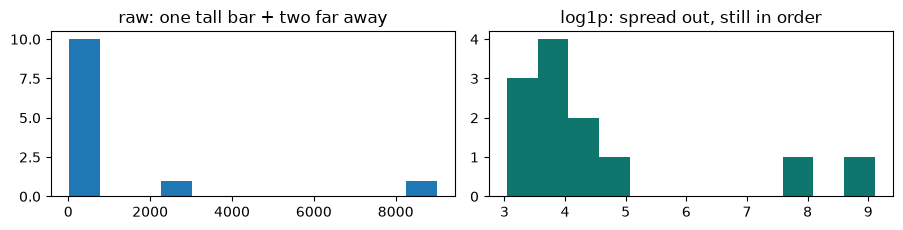

In [32]:
# ▶️ Run: monthly revenue of 12 accounts: most are small, two are huge
revenue = pd.Series([20, 25, 30, 35, 40, 45, 50, 60, 80, 120, 2500, 9000], name="monthly_revenue_eur")
fig, axes = plt.subplots(1, 2, figsize=(9, 2.4))
axes[0].hist(revenue, bins=12); axes[0].set_title("raw: one tall bar + two far away")
axes[1].hist(np.log1p(revenue), bins=12, color="#0f766e"); axes[1].set_title("log1p: spread out, still in order")
plt.tight_layout(); plt.show()

## Step 8 · Put it together: a model-ready training table

In [33]:
# ▶️ Run: impute + scale the numbers, impute + one-hot the words, then glue the pieces side by side
word_columns = ["species", "island", "sex"]
word_imputer = SimpleImputer(strategy="most_frequent").set_output(transform="pandas")
word_encoder = OneHotEncoder(drop="first", sparse_output=False).set_output(transform="pandas")
words_train = word_encoder.fit_transform(word_imputer.fit_transform(X_train[word_columns]))

X_train_ready = pd.concat([numbers_train_scaled, words_train], axis=1)
X_train_ready.head()

,bill_length_mm,bill_depth_mm,flipper_length_mm,species_Chinstrap,species_Gentoo,island_Dream,island_Torgersen,sex_Male
24,-1.609345,0.912671,-1.026657,0.0,0.0,0.0,0.0,0.0
323,0.590783,-1.658721,-0.226694,0.0,1.0,0.0,0.0,0.0
143,-1.242657,-0.146138,-0.663037,0.0,0.0,1.0,0.0,0.0
208,0.957471,1.416865,0.136925,1.0,0.0,1.0,0.0,1.0
253,0.920802,-1.154526,1.373232,0.0,1.0,0.0,0.0,0.0


In [34]:
# ✅ Check
assert X_train_ready.shape == (256, 8)
assert X_train_ready.isna().sum().sum() == 0
assert X_train_ready.index.equals(y_train.index)
print("✅ Model-ready: 256 penguins × 8 columns, only numbers, no gaps, rows still match y_train.")

✅ Model-ready: 256 penguins × 8 columns, only numbers, no gaps, rows still match y_train.


## 📋 Choosing a transformation (starting points, not rules)

| problem | starting option | watch out |
|---|---|---|
| missing numbers | median imputation (learned on training data) | ask *why* it's missing; missing ≠ zero |
| missing categories | most frequent value, or an explicit "missing" category | imputation can hide meaningful missingness: add a flag |
| categories without order | one-hot encoding | decide what happens to unseen categories; many categories → many columns |
| categories with a real order | ordinal encoding with the order written out | equal steps assume equal distances |
| different units | Standard, MinMax or Robust scaling | model-dependent; no scaler removes outliers |
| very skewed positive numbers | log (`log1p`) | values must be ≥ 0; check it actually helps |

## ✅ Check your understanding

1. What is the difference between `fit` and `transform`? Which one may touch the test set?
2. Why could coding lunches as 0, 1, 2, 3, 4 mislead a linear model or KNN?
3. Does `RobustScaler` remove extreme values?

**Your answers to 1–3:**

**✍️ Sample answer:** (1) `fit` learns numbers (median, categories, mean/SD) from data; `transform` applies them. Only `transform` may touch test or new rows. (2) The codes invent an order and distances (soup "4× further" from burger than cereal), which the model treats as real. One-hot avoids that. (3) No. It only learns its ruler from the median and IQR, so extremes don't distort the ruler, but they stay extreme after scaling.

### 🎉 Well done! Next: notebook 2, *build the snowman table yourself.*